# Analyze an NWB recording and save the results

**Question:** How can I load a session from NWB, calculate firing-rate maps,
and save the results so I can use them again? We keep the unit IDs, recording
periods, coordinate units, and analysis settings with the maps.

**You will need:** An NWB file containing position tracking and unit spike
times. The recorded periods must also be known. We create a small synthetic
file below so you can run the whole workflow without downloading a recording.

**Estimated time**: 15-20 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb).

Install the optional NWB dependencies before running this notebook:
`uv sync --extra notebooks --extra nwb` from the repository root, then select
that environment's kernel.

In [1]:
import shutil
import sys
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

try:
    from pynwb import NWBHDF5IO, NWBFile
    from pynwb.behavior import Position, SpatialSeries
except ImportError as error:
    raise ImportError(
        "This notebook requires neurospatial[nwb]. In a checkout run "
        "`uv sync --extra notebooks --extra nwb`, then restart the kernel."
    ) from error

from neurospatial import Environment
from neurospatial.encoding import compute_spatial_rates
from neurospatial.io.nwb import (
    environment_from_position,
    read_position,
    read_spatial_rates,
    read_units,
    write_spatial_rates,
)
from neurospatial.simulation import (
    PlaceCellModel,
    generate_poisson_spikes,
    simulate_trajectory_ou,
)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(10, 5))

### Example file

The next cell creates an NWB recording with 50 Hz tracking and two simulated
place cells in a 100 cm square arena. Spikes and positions share a clock in
seconds. There is a 20 s electrophysiology gap, from 75 to 95 s.

This is only example-data preparation; loading and analysis begin in
section 1. The simulated neurons have unit IDs 7 and 42, and independent
random streams generate the trajectory and each spike train.

In [2]:
sim_env = Environment.from_grid_mask(
    np.ones((20, 20), dtype=bool),
    grid_edges=(np.arange(0, 105, 5.0), np.arange(0, 105, 5.0)),
)
sim_env = sim_env.with_metadata(units="cm")
positions, times = simulate_trajectory_ou(
    sim_env, duration=180.0, dt=0.02, speed_units="cm", speed_mean=15.0, seed=42
)
coverage = np.array([[times[0], 75.0], [95.0, times[-1]]])
unit_ids = np.array([7, 42])
spike_trains = []
for center, seed in [([40.0, 50.0], 142), ([60.0, 50.0], 143)]:
    model = PlaceCellModel(
        sim_env, center=center, width=12.0, max_rate=25.0, baseline_rate=0.5
    )
    spikes = generate_poisson_spikes(
        model.firing_rate(times, positions), times, seed=seed
    )
    observed = np.zeros(spikes.size, dtype=bool)
    for start, stop in coverage:
        observed |= (spikes >= start) & (spikes < stop)
    spike_trains.append(spikes[observed])

nwbfile = NWBFile(
    session_description="Synthetic recording for the neurospatial NWB workflow",
    identifier="neurospatial-synthetic-nwb-workflow",
    session_start_time=datetime(2026, 1, 1, tzinfo=timezone.utc),
)
tracking = Position(name="Position")
tracking.add_spatial_series(
    SpatialSeries(
        name="head_position",
        data=positions / 10.0,
        conversion=10.0,
        timestamps=times,
        unit="centimeters",
        reference_frame="Arena corner (0, 0)",
        description="Stored values times conversion give positions in centimeters",
    )
)
nwbfile.create_processing_module("behavior", "Behavioral tracking").add(tracking)
for unit_id, spikes in zip(unit_ids, spike_trains, strict=True):
    nwbfile.add_unit(id=int(unit_id), spike_times=spikes, obs_intervals=coverage)

temporary_data = tempfile.TemporaryDirectory(prefix="neurospatial-nwb-workflow-")
output_dir = Path(temporary_data.name)
source_path = output_dir / "source_recording.nwb"
analysis_path = output_dir / "recording_with_analysis.nwb"
with NWBHDF5IO(str(source_path), "w") as io:
    io.write(nwbfile)
print(
    f"Wrote {source_path.name}: {len(times):,} tracking samples, {len(unit_ids)} units"
)

Wrote source_recording.nwb: 9,000 tracking samples, 2 units


## 1. Load position, spike trains, and recorded periods

`source_path` points to the input NWB file. Read positions and spike times
inside the `with` block; by default they are loaded into memory and remain
available after the file closes. We select neurons by their unit IDs, in the
order 42, then 7.

Check the position units before choosing spatial bin widths. `read_position`
applies the NWB conversion and offset to the stored values. `read_units`
gives the periods when all selected units were being recorded as
`units.spike_window`. These periods come from `obs_intervals`, not from the
first and last spikes: a quiet neuron can still have been recorded.

In [3]:
with NWBHDF5IO(str(source_path), "r") as io:
    recording = io.read()
    pos = read_position(
        recording, processing_module="behavior", position_name="head_position"
    )
    units = read_units(recording, unit_ids=[42, 7])  # deliberate label order
    if pos.units is None:
        raise ValueError("Resolve tracking units from the experiment before binning.")
    env = environment_from_position(
        recording,
        bin_size=5.0,
        units=pos.units,
        processing_module="behavior",
        position_name="head_position",
    )

print(f"Position units: {pos.units}; units loaded: {units.unit_ids.tolist()}")
print(f"Periods when all selected units were recorded (s):\n{units.spike_window}")

Position units: cm; units loaded: [42, 7]
Periods when all selected units were recorded (s):
[[  0.    75.  ]
 [ 95.   179.98]]


The checks below compare the loaded values with the generated example data.
They confirm that coordinate conversion, unit selection, and recorded periods
were read correctly. Skip this example-only cell when loading your own file.

In [4]:
np.testing.assert_allclose(pos.positions, positions)
np.testing.assert_array_equal(units.unit_ids, [42, 7])
np.testing.assert_array_equal(units.spike_window, coverage)

## 2. Choose the analysis period and estimate firing-rate maps

Use 5 cm spatial bins, 6 cm smoothing, and a minimum of 0.1 s occupancy per
bin. `epochs` chooses the session period to analyze; we leave out the first
and last 5 s. `spike_window` also removes the electrophysiology gap. Tracking
continues during that gap, but those seconds must not enter the firing-rate
denominator.

Here the spatial grid comes from the range of the tracking coordinates.
Use measured arena boundaries when those are a better description of the
accessible space. Bins without enough recorded occupancy remain NaN in the
maps. An unvisited location does not provide evidence for zero firing.

         Peak rate (Hz)  Peak x (cm)  Peak y (cm)
unit_id                                          
42                20.69        60.01        40.05
7                 19.34        45.01        45.05
Spatial bins used for rate maps: 255 / 301


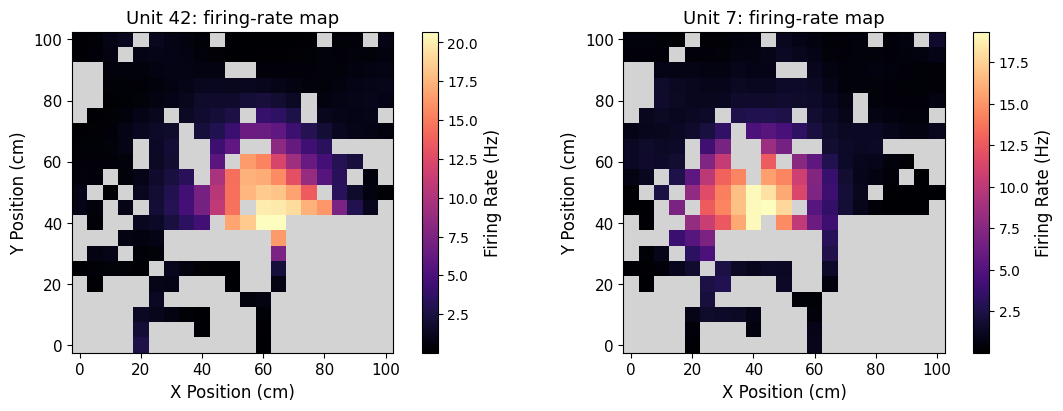

In [5]:
rates = compute_spatial_rates(
    env,
    units.spike_times,
    pos.times,
    pos.positions,
    unit_ids=units.unit_ids,
    epochs=[[pos.times[0] + 5.0, pos.times[-1] - 5.0]],
    spike_window=units.spike_window,
    bandwidth=6.0,
    min_occupancy=0.1,
)
peak_summary = rates.summary_table(include_classification=False)[
    ["peak_firing_rate", "peak_x", "peak_y"]
].rename(
    columns={
        "peak_firing_rate": "Peak rate (Hz)",
        "peak_x": f"Peak x ({pos.units})",
        "peak_y": f"Peak y ({pos.units})",
    }
)
print(peak_summary.round(2))
print(f"Spatial bins used for rate maps: {rates.spatial_support.sum()} / {env.n_bins}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, unit_id in zip(axes, rates.unit_ids, strict=True):
    rates.sel(unit_id=int(unit_id)).plot(ax=ax, cmap="magma")
    ax.set_title(f"Unit {unit_id}: firing-rate map")
plt.show()

Inspect the location of each firing-rate peak and the regions left blank.
Unit 7 was simulated with a field centered at (40, 50) cm, and unit 42 at
(60, 50) cm; sampling and smoothing affect the estimated shapes. The summary above
describes the maps without assigning cell-type labels. In an experiment,
evaluating spatial selectivity requires more than saving or plotting a map.

## 3. Save the maps in an analysis copy of the recording

Copy the input file to `analysis_path`, add the results, and save the copy.
`write_spatial_rates` keeps the maps, occupancy, unit IDs, valid spatial bins,
arena geometry, and analysis settings together in the file's `/analysis`
group, where any NWB reader can find them. Because the unit IDs are IDs of
the file's units table, each map is also linked to its unit's row. Calling
`io.write` writes those changes to disk.

Reopen the saved file and load the maps with `read_spatial_rates`.

In [6]:
shutil.copy2(source_path, analysis_path)
with NWBHDF5IO(str(analysis_path), "a") as io:
    analysis_file = io.read()
    write_spatial_rates(analysis_file, rates, name="spatial_rates")
    io.write(analysis_file)

with NWBHDF5IO(str(analysis_path), "r") as io:
    restored = io.read()
    pos_back = read_position(restored, position_name="head_position")
    units_back = read_units(restored, unit_ids=[42, 7])
    rates_back = read_spatial_rates(restored, name="spatial_rates")

## 4. Check that the saved maps match the analysis

Compare the reloaded firing rates, unit IDs, and settings after closing the
file. A successful comparison means another session can recover the same
saved analysis, including the choices used to estimate the maps.

In [7]:
np.testing.assert_allclose(rates_back.firing_rates, rates.firing_rates, equal_nan=True)
np.testing.assert_array_equal(rates_back.unit_ids, rates.unit_ids)
assert rates_back.analysis_settings == rates.analysis_settings
print("Reloaded firing-rate maps, unit IDs, and analysis settings match.")
print(
    f"Analysis copy: {analysis_path.name} ({analysis_path.stat().st_size / 1e6:.2f} MB)"
)

Reloaded firing-rate maps, unit IDs, and analysis settings match.
Analysis copy: recording_with_analysis.nwb (0.56 MB)


Additional checks below confirm that position, spikes, occupancy, recorded
periods, and coordinate units also survived saving. They check this example's
grid geometry, including how points outside the arena are assigned to bins.

In [8]:
np.testing.assert_allclose(pos_back.positions, pos.positions)
np.testing.assert_array_equal(units_back.unit_ids, units.unit_ids)
np.testing.assert_array_equal(units_back.spike_window, units.spike_window)
for train_back, train in zip(units_back.spike_times, units.spike_times, strict=True):
    np.testing.assert_array_equal(train_back, train)
np.testing.assert_array_equal(rates_back.occupancy, rates.occupancy)
np.testing.assert_array_equal(rates_back.spatial_support, rates.spatial_support)
np.testing.assert_array_equal(rates_back.spike_window, rates.spike_window)
np.testing.assert_array_equal(rates_back.env.bin_centers, env.bin_centers)
assert set(rates_back.env.connectivity.edges) == set(env.connectivity.edges)
assert rates_back.env.units == env.units == pos_back.units == "cm"
outside = np.array([[-100.0, -100.0]])
np.testing.assert_array_equal(rates_back.env.bin_at(outside), env.bin_at(outside))
print(
    "Additional checks passed: position, spikes, occupancy, recorded periods, and arena geometry."
)

Additional checks passed: position, spikes, occupancy, recorded periods, and arena geometry.


## Use your own recording

Set `source_path` to your NWB file and `analysis_path` to a separate output
file you want to keep. Start at section 1, skipping example-file preparation,
the checks against generated data, and the temporary-file cleanup below.
Match `processing_module` and `position_name` to your tracking data, and
replace `unit_ids=[42, 7]` with the units you want to analyze.

Replace `epochs` in the rate-map calculation with your chosen session periods.
Check that position units, bin width, smoothing width, and occupancy threshold
suit your experiment. Confirm the units table describes recorded periods
correctly before using `units.spike_window`. Check saved spatial operations
needed by your analysis, particularly when using a layout other than a grid.

The default readers load arrays into memory. If you use `lazy=True` to read
from disk as needed, keep the file open; lazy position reads also require
identity conversion and offset. For files using ndx-pose or ndx-events,
import those extension packages before opening the file. This example only
uses standard NWB containers.

[Firing around a cue](07_peri_event_analysis.ipynb) uses event times and
spike recording periods. [Real-data analysis](04_real_data_analysis.ipynb)
follows a recording from tracking and spikes to spatial analysis.

The final cell removes this notebook's temporary example files. The loaded
arrays and calculated results remain available in memory.

In [9]:
temporary_data.cleanup()